<h1>Section 4 – Language Models exploration</h1>
In this task, the objective is to harness the capabilities of language models like Bert or Word2Vec, for
supervised learning.
Two interesting concepts play a role when we use neural networks:
1- Itis possible to do transfer learning, i.e., to take a model that have been trained with other
enormous datasets by Big Tech companies, and we can do fine-tuning i.e., to train this model
starting from its pre-trained version.
2- In NLP tasks, words/documents are transformed into vectors (encoding) and this task is
Unsupervised, so we can use a much larger amount of data.
Choose a language model between Bert and Doc2Vec (word2vec for documents), then:
<h2>Perform text embedding on comments</h2>
i.e., body column in data_unsupervised.csv.

<s>a. If you choose Doc2Vec, pretrain Doc2Vec based on the comments. Save the embedding
vectors or model for next steps.</s>

b. If you choose Bert, take the pretrained Bert model like in this example from HuggingFace.
You only need the embedding vectors from the model rather than other down-stream task
capabilities, so just take the base model and extract the embeddings for the following
steps. And you are not required to do fine-tuning here. You can use the Bert, DistillBert
(light version of Bert, smaller, faster), or any other Bert variations.

In [2]:
#!pip install transformers
#!pip install torch
#!pip install imbalanced-learn

In [3]:
from transformers import DistilBertTokenizer, DistilBertModel
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
import numpy as np
import torch

/home/jack/ML4NProject/reddit2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# data=pd.read_csv("data_supervised.csv", encoding="utf8")

# data['body'] = data['body'].str.lower()#to lowercase
# data['body'] = data['body'].str.replace(r'http\S+|www\.\S+', '', regex=True)#remove URLs
# data['body'] = data['body'].str.replace(r'[^a-z\s]', '', regex=True)#remove everything except letters and whitespace
# data = data[data['body'].str.strip().astype(bool)]#remove empty comments
# data=data.drop_duplicates()#remove duplicates

# from langdetect import detect, DetectorFactory
# DetectorFactory.seed = 0  # rende i risultati stabili

# # Assicuriamoci che 'body' sia stringa
# data['body'] = data['body'].fillna('').astype(str)

# # Applichiamo il rilevamento lingua gestendo errori e testi vuoti
# langs = []
# for text in data['body']:
#     # if not text.strip():  # se la riga del commento è vuota
#     #     langs.append("empty")
#     # else:
#     try:
#         langs.append(detect(text))
#     except:
#         langs.append("error")

# data['language'] = langs

# # Conta quante frasi ci sono per ciascuna lingua
# counts = data['language'].value_counts()
# print(counts)

# data.to_csv("data_supervised_lang.csv", index=False)

<h3>Data reading</h3>

In [5]:
data = pd.read_csv('data_supervised_lang.csv')
data = data[data['language'] == 'en'] #keep only English comments
data=data[['author','body','subreddit']].groupby('author').agg(' '.join).reset_index()

In [6]:
#distilbert smaller but faster model
#uncased -> not case-sensitive

#Load pre-trained tokenizer (vocabulary)
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')
#Load pre-trained model
model = DistilBertModel.from_pretrained('distilbert-base-uncased')
model.eval()

# Function to get embeddings for a list of texts
def get_embeddings(texts, tokenizer, model, max_length=128):
    embeddings = []
    with torch.no_grad():
        count=0 # Just to understand how much time this takes
        for text in texts:
            inputs = tokenizer(text, return_tensors='pt', truncation=True, padding='max_length', max_length=max_length)
            outputs = model(**inputs)
            # Use the [CLS] token embedding as sentence embedding
            cls_embedding = outputs.last_hidden_state[:, 0, :].squeeze().numpy()
            embeddings.append(cls_embedding)
            count += 1
            if count % 10000 == 0:
                print(f"Processed {count} comments")
    return embeddings

# Get embeddings for all comments in 'body'
embeddings = get_embeddings(data['body'].tolist(), tokenizer, model)

<h2>Feature Concatenation.</h2>
For each user, create a feature vector where each column x represents the fraction of times the
user has posted in the x-th subreddit (and reduce the cardinality of the matrix with PCA).
Concatenate the embedding vectors output by the model you chose at step a with these new
features.

In [7]:
subreddits = data['subreddit'].unique()
user_subreddit_counts = data.groupby(['author', 'subreddit']).size().unstack(fill_value=0)
user_total_comments = user_subreddit_counts.sum(axis=1)
user_sub_fraction = user_subreddit_counts.div(user_total_comments, axis=0)
user_sub_fraction = user_sub_fraction.reindex(columns=subreddits, fill_value=0)

# user_sub_fraction is a DataFrame where rows are users and columns are subreddits,
# and values are the fraction of comments in each subreddit for each user
user_sub_fraction.head()

subreddit,tall pics StarWars AskReddit AskReddit,gainit,MouseReview MechanicalKeyboards jailbreak jailbreak jailbreak jailbreak jailbreak jailbreak jailbreak AskReddit,AskWomen AskWomen AskWomen AskWomen AskWomen AskWomen AskWomen AskWomen AskMen,mildlyinteresting todayilearned,tipofmytongue ifyoulikeblank ifyoulikeblank,myfriendwantstoknow,AskReddit,trees trees bestof bestof IAmA,gonewild dirtypenpals dirtypenpals dirtypenpals dirtypenpals AdviceAnimals gifs gifs gifs gifs gifs gifs gifs worldnews worldnews worldnews worldnews worldnews worldnews worldnews worldnews worldnews worldnews worldnews AskReddit AskReddit AskReddit AskReddit AskReddit AskReddit news AskReddit AskReddit AskReddit AskReddit todayilearned AskReddit AskReddit gifs Bad_Cop_No_Donut gonewild gonewild gonewild gonewild IAmA IAmA WTF WTF WTF WTF WTF,...,feedthebeast feedthebeast feedthebeast pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast mindcrack feedthebeast pcmasterrace pcmasterrace pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace pcmasterrace pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace pcmasterrace,TransSpace AskReddit BDSMcommunity AskMen,OkCupid xxketo OkCupid OkCupid OkCupid femalefashionadvice AskWomen AskWomen AskWomen AskWomen AskWomen amiugly AskWomen amiugly xxketo xxketo xxketo AskWomen AskWomen AskMen MorbidReality AskWomen KitchenConfidential AskReddit AskWomen Baking femalefashionadvice femalefashionadvice UCSantaBarbara food AskWomen AskWomen AskWomen KitchenConfidential KitchenConfidential KitchenConfidential KitchenConfidential KitchenConfidential KitchenConfidential femalefashionadvice,CrossStitch Watches makeupexchange FancyFollicles,AskReddit AskReddit RandomActsOfPolish Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon RandomActsOfPolish RandomActsOfPolish RandomActsOfPolish RandomActsOfPolish Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon RandomActsOfPolish Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Ama

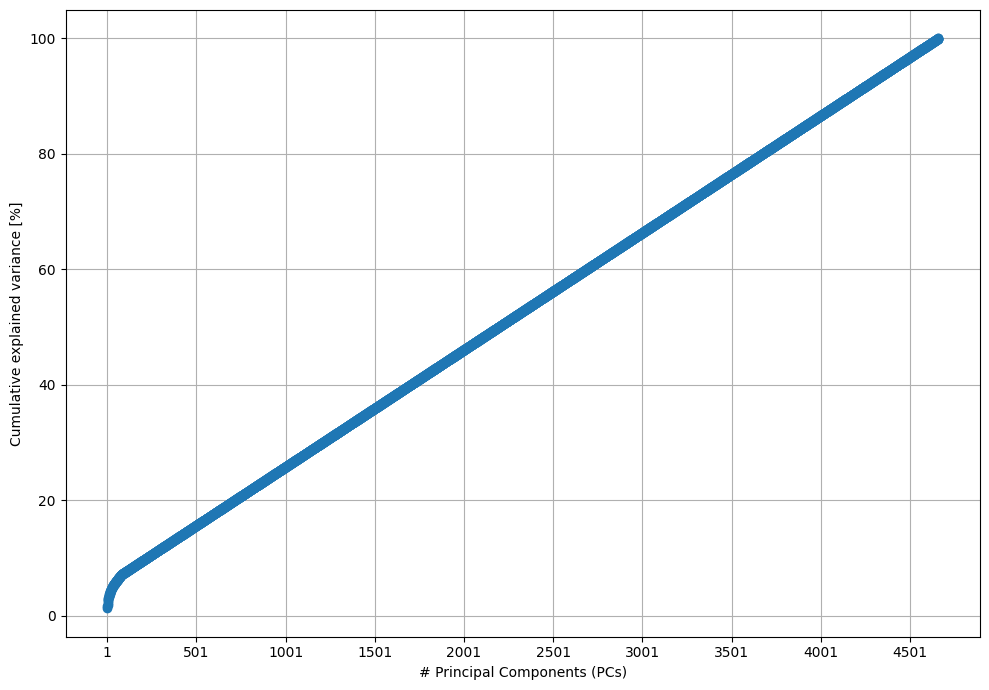

In [8]:
pca=PCA(random_state=42)
pca=pca.fit(user_sub_fraction)

explained_variance = pca.explained_variance_ratio_
cumul_exp_var = np.cumsum(explained_variance)
perc_cumul_exp_var = cumul_exp_var * 100

# make the plot of cumulative explained variance wrt number of components
plt.figure(figsize=(10, 7))
plt.plot(perc_cumul_exp_var, marker='o')
plt.xlabel('# Principal Components (PCs)')
plt.ylabel('Cumulative explained variance [%]')
plt.xticks([i for i in range(0,user_sub_fraction.shape[1],500)], [i for i in range(1,user_sub_fraction.shape[1]+1,500)])
plt.grid()
plt.tight_layout()
plt.show()

In [12]:
pca=PCA(random_state=42,n_components=3500)
pca=pca.fit(user_sub_fraction)
X_pca=pca.transform(user_sub_fraction)

#Print the explained variance with 3500 components
explained_variance_3500 = pca.explained_variance_ratio_
cumul_exp_var_3500 = np.cumsum(explained_variance_3500)
perc_cumul_exp_var_3500 = cumul_exp_var_3500 * 100
print(perc_cumul_exp_var_3500)

[ 1.3404628   1.66399674  1.96814579 ... 76.4582717  76.4785483
 76.49882491]


In [9]:
# Convert X_pca to DataFrame
X_pca_df = pd.DataFrame(X_pca, index=user_sub_fraction.index)

# Convert embeddings to DataFrame
embeddings_df = pd.DataFrame(embeddings)
embeddings_df.index = user_sub_fraction.index  # Align indices with user_sub_fraction
# Concatenate PCA features and embeddings
X_combined = pd.concat([X_pca_df, embeddings_df], axis=1)

X_combined.to_csv('X_combined.csv')
#X_combined = embeddings_df


<h2>3. Build and fine-tune a classification model.</h2>
a. Build a basic multilayer perceptron (MLP) to perform classification based on the
concatenated features at the previous step. Fine-tune it on the supervised training set for N
epochs, like what you did in Section 2.

b. Plot the learning curves on training and validation set. After how many epochs should we
stop the training?

Here is the thing performed in this section

3 Hidden layer model

&nbsp;&nbsp;&nbsp;&nbsp;1. Train with a grid of parameters to decide which parameters to use

&nbsp;&nbsp;&nbsp;&nbsp;2. Train a model using the best parameters from before (more epochs)

&nbsp;&nbsp;&nbsp;&nbsp;3. Plot recall, accuracy, precision, f1, ROC, AUC, confusion matrix on validation set

&nbsp;&nbsp;&nbsp;&nbsp;4. Plot recall, accuracy, precision, f1, ROC, AUC, confusion matrix on test set

2 Hidden layer model

&nbsp;&nbsp;&nbsp;&nbsp;1. Train with a grid of parameters to decide which parameters to use

&nbsp;&nbsp;&nbsp;&nbsp;2. Train a model using the best parameters from before (more epochs)

&nbsp;&nbsp;&nbsp;&nbsp;3. Plot recall, accuracy, precision, f1, ROC, AUC, confusion matrix on validation set

&nbsp;&nbsp;&nbsp;&nbsp;4. Plot recall, accuracy, precision, f1, ROC, AUC, confusion matrix on test set

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, roc_curve, auc, precision_recall_curve, average_precision_score

import torch
from torch import nn
import torch.nn.functional as F
import itertools

In [2]:
try:
    del data, embeddings, pca, subreddits, user_sub_fraction, user_subreddit_counts, user_total_comments, X_pca
except NameError:
    pass

X_combined = pd.read_csv('X_combined.csv', index_col=0)
target_df=pd.read_csv('target_supervised.csv')
target_df = target_df.set_index('author').loc[X_combined.index].reset_index()

X_train, X_test, y_train, y_test = train_test_split(X_combined, target_df['gender'], stratify=target_df['gender'], train_size=0.85, random_state=15)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, stratify=y_train, train_size=0.7/0.85, random_state=15)

print(X_train.shape, X_val.shape, X_test.shape)

scaler = StandardScaler()
scaler.fit(X_train)
X_train_s, X_val_s, X_test_s = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)

X_train = torch.tensor(X_train_s, dtype=torch.float)
y_train = torch.tensor(y_train.values, dtype=torch.long)
X_val = torch.tensor(X_val_s, dtype=torch.float)
y_val = torch.tensor(y_val.values, dtype=torch.long)
X_test = torch.tensor(X_test_s, dtype=torch.float)
y_test = torch.tensor(y_test.values, dtype=torch.long)

(3453, 4268) (740, 4268) (741, 4268)


In [3]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred))
    return acc

def confusion_matrix(y_true, y_pred):
    df = pd.DataFrame([x for x in zip([x.item() for x in y_true], [x.item() for x in y_pred])], columns=['y_true', 'y_pred'])
    df[['samples']] = 1
    confusion = pd.pivot_table(df, index='y_true', columns='y_pred', values='samples', aggfunc="sum")
    plt.figure()
    sns.heatmap(confusion, cmap='Blues', annot=True, cbar_kws={'label':'Occurrences'}, fmt='g')
    plt.xlabel('Prediction')
    plt.ylabel('True')    
    plt.title('Confusion matrix')
    plt.show()

<h3>Trying a model with 3 hidden layers</h3>

In [4]:
# Define the neural network
class Model_classification(nn.Module): 
    def __init__(
        self, 
        in_features, # number of input features
        out_features, # number of output features
        hidden_1, # number of neurons in the 1st hidden layer
        hidden_2, # number of neurons in the 2nd hidden layer
        hidden_3 # number of neurons in the 3rd hidden layer
    ):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=in_features, out_features=hidden_1) # 1st linear layer
        self.layer_2 = nn.Linear(in_features=hidden_1, out_features=hidden_2) # 2nd linear layer
        self.layer_3 = nn.Linear(in_features=hidden_2, out_features=hidden_3) # 3rd linear layer

        self.layer_output = nn.Linear(in_features=hidden_3, out_features=out_features) # output layer
        self.activation_1 = nn.Tanh() # activation function
        #self.activation_2 = nn.Softmax(dim=1) # activation function

    # define feedforward process
    def forward(self, x):
        #x = x.flatten(start_dim=1) #to go from 28x28 image tensor to 784 input tensor
        out = self.activation_1(self.layer_1(x)) #output of 1st hidden layer
        out = self.activation_1(self.layer_2(out)) #output of 2nd hidden layer
        out = self.activation_1(self.layer_3(out))
        #out = self.activation_2(self.layer_output(out)) #output of the nn
        out = self.layer_output(out) 
        
        return out

In [5]:
torch.manual_seed(8)
dim_features = X_combined.shape[1]#This is the size of input features
loss_fn = nn.CrossEntropyLoss()

In [6]:
def create_batches(data, labels, batch_size):
    num_samples = data.shape[0]
    batches = []
    for i in range(0, num_samples, batch_size):
        data_batch = data[i:i + batch_size]
        label_batch = labels[i:i + batch_size]
        batches.append((data_batch, label_batch))
    return batches

<h4>Train models to find the best parameters</h4>

In [ ]:
# Define parameter grid
param_grid = {
    'learning_rate': [1e-5],
    'hidden_1': [1000,  2000, 4000],
    'hidden_2': [1500, 750, 2500],
    'hidden_3': [250, 500, 1000],
    'batch_size': [32, 64]
}

# Generate all combinations
keys, values = zip(*param_grid.items())
param_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

best_val_acc = 0
best_params = None

for params in param_combinations:
    # Create model with current parameters
    model = Model_classification(
        in_features=dim_features,
        out_features=2,
        hidden_1=params['hidden_1'],
        hidden_2=params['hidden_2'],
        hidden_3=params['hidden_3']
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=params['learning_rate'])
    batch_size = params['batch_size']
    batches = create_batches(X_train, y_train, batch_size)

    epoch = 0
    current_max_acc = 0
    stop = False
    max_cumulated_epochs = 5
    current_cumulated_epochs = 0
    
    while not stop:
        # model training phase
        model.train()
        for _, (data_batch, label_batch) in enumerate(batches):
            y_prob = model(data_batch).squeeze() # get the output probability of predictions
            loss_batch = loss_fn(y_prob, label_batch) # calculate the loss
            optimizer.zero_grad() # reset the gradients of model parameters
            loss_batch.backward() # backpropagate the prediction loss
            optimizer.step() # adjust the parameters by the gradients 

        # model evaluation phase
        model.eval()
        
        # training set
        y_prob = model(X_train).squeeze()
        y_pred = torch.argmax(y_prob, dim=-1) # get the label
        acc_train = accuracy_fn(y_true=y_train, y_pred=y_pred)

        # validation set
        y_prob = model(X_val).squeeze()
        y_pred = torch.argmax(y_prob, dim=-1) 
        acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)

        if current_max_acc -  acc_val < 0: 
            current_max_acc =  acc_val
        else:
            current_cumulated_epochs += 1
            if current_cumulated_epochs >= max_cumulated_epochs:
                stop = True

        if acc_train==1.0:
            stop=True

    print(f"Params: {params}, Val Acc: {acc_val:.4f}")
    if acc_val > best_val_acc:
        best_val_acc = acc_val
        best_params = params

print("Best parameters:", best_params, "accuracy value:", best_val_acc)

Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 250, 'batch_size': 32}, Val Acc: 0.7041
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 250, 'batch_size': 64}, Val Acc: 0.7176
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 500, 'batch_size': 32}, Val Acc: 0.7068
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 500, 'batch_size': 64}, Val Acc: 0.7176
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 1000, 'batch_size': 32}, Val Acc: 0.7365
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 1000, 'batch_size': 64}, Val Acc: 0.7162
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 250, 'batch_size': 32}, Val Acc: 0.7095
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 250, 'batch_size': 64}, Val Acc: 0.7068
Params: {'learning_rate': 1e-05,

In [7]:
# To analyze results without executing the whole grid search again
best_params = {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 1000, 'batch_size': 32}

<h4> Train the model with the best parameters found in best_params</h4>


In [8]:
# Train the model with the best parameters found in best_params
model = Model_classification(
    in_features=dim_features,
    out_features=2,
    hidden_1=best_params['hidden_1'],
    hidden_2=best_params['hidden_2'],
    hidden_3=best_params['hidden_3']
)
optimizer = torch.optim.Adam(model.parameters(), lr=best_params['learning_rate'])

batch_size = best_params['batch_size']
batches = create_batches(X_train, y_train, batch_size)

epoch=0
loss_train_all = []
loss_val_all = []
acc_train_all = []
acc_val_all = []
current_max_acc = 0
current_cumulated_epochs = 0
max_cumulated_epochs = 10
stop = False

while not stop:
    # Training phase
    model.train()
    loss_all = []
    for data_batch, label_batch in batches:
        y_prob = model(data_batch)
        loss = loss_fn(y_prob, label_batch)
        loss_all.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    # Evaluation phase
    model.eval()
    with torch.no_grad():
        # Training set
        y_prob_train = model(X_train)
        y_pred_train = torch.argmax(y_prob_train, dim=1)
        acc_train = accuracy_fn(y_train, y_pred_train)
        
        # Validation set
        y_prob_val = model(X_val)
        loss_val = loss_fn(y_prob_val, y_val)
        y_pred_val = torch.argmax(y_prob_val, dim=1)
        acc_val = accuracy_fn(y_val, y_pred_val)
    
    # Collect results
    loss_train_all.append(np.mean(loss_all))
    loss_val_all.append(loss_val.item())
    acc_train_all.append(acc_train)
    acc_val_all.append(acc_val)
    
    print(f'Epoch: {epoch+1} | Train Loss: {loss_train_all[-1]:.5f}, Val Loss: {loss_val_all[-1]:.5f}, Train Acc: {acc_train:.4f}, Val Acc: {acc_val:.4f}')
    epoch += 1

    # if the evaluated accuracy is not larger than the maximum accuracy recorded, we increase the cumulation of epochs of 1
    if current_max_acc -  acc_val < 0: 
        current_max_acc =  acc_val
        #save model state
        torch.save(model.state_dict(), 'best_model.pth')
    else:
        current_cumulated_epochs += 1
        if current_cumulated_epochs >= max_cumulated_epochs:
            stop = True

# Load the best model
model.load_state_dict(torch.load('best_model.pth'))

Epoch: 1 | Train Loss: 0.63578, Val Loss: 0.59183, Train Acc: 0.7570, Val Acc: 0.7162
Epoch: 2 | Train Loss: 0.52404, Val Loss: 0.54004, Train Acc: 0.8175, Val Acc: 0.7324
Epoch: 3 | Train Loss: 0.42606, Val Loss: 0.51406, Train Acc: 0.8989, Val Acc: 0.7392
Epoch: 4 | Train Loss: 0.30601, Val Loss: 0.51203, Train Acc: 0.9681, Val Acc: 0.7486
Epoch: 5 | Train Loss: 0.18155, Val Loss: 0.55337, Train Acc: 0.9890, Val Acc: 0.7365
Epoch: 6 | Train Loss: 0.09797, Val Loss: 0.62876, Train Acc: 0.9916, Val Acc: 0.7243
Epoch: 7 | Train Loss: 0.05807, Val Loss: 0.71045, Train Acc: 0.9942, Val Acc: 0.7284
Epoch: 8 | Train Loss: 0.03978, Val Loss: 0.78575, Train Acc: 0.9951, Val Acc: 0.7135
Epoch: 9 | Train Loss: 0.02942, Val Loss: 0.85533, Train Acc: 0.9965, Val Acc: 0.7081
Epoch: 10 | Train Loss: 0.02250, Val Loss: 0.92068, Train Acc: 0.9977, Val Acc: 0.7095
Epoch: 11 | Train Loss: 0.01745, Val Loss: 0.98341, Train Acc: 0.9980, Val Acc: 0.7068
Epoch: 12 | Train Loss: 0.01356, Val Loss: 1.04448, 

<All keys matched successfully>

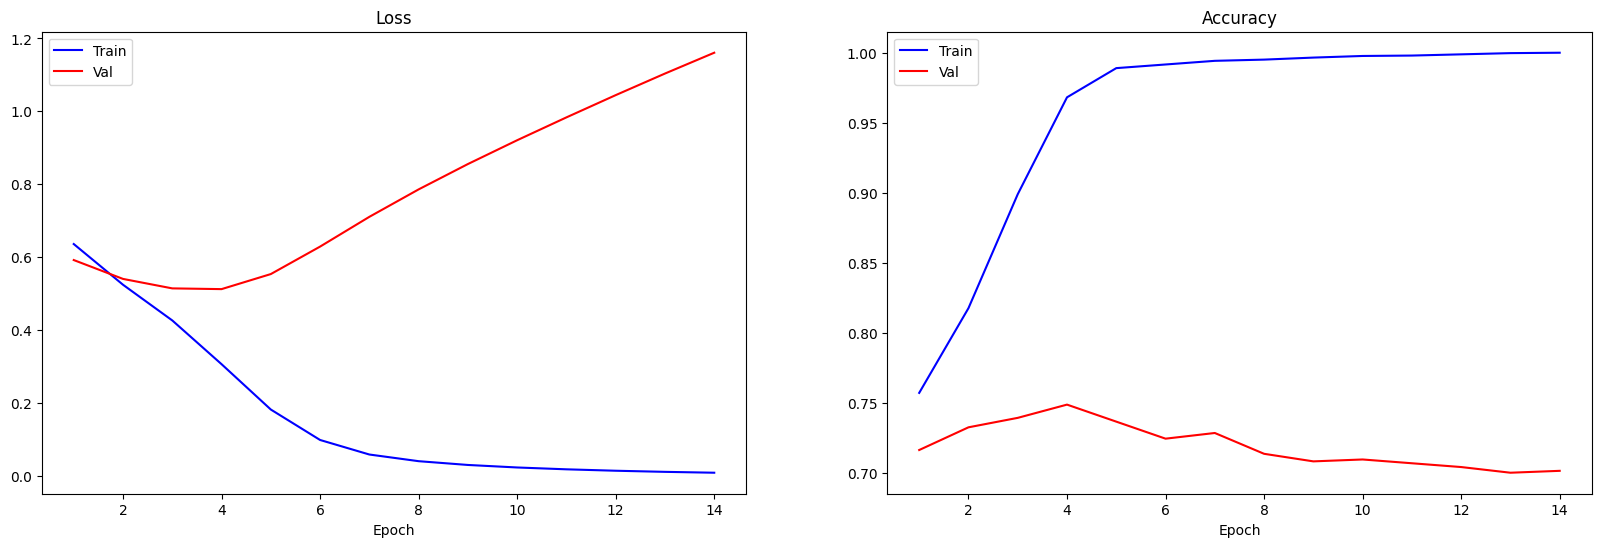

In [9]:
# visualize the evolution of losses and accuracies
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(20,6))

ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.plot(range(1, len(loss_train_all) + 1), loss_train_all, label='Train', color='blue')
ax1.plot(range(1, len(loss_val_all) + 1), loss_val_all, label='Val', color='red')
ax1.legend()

ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.plot(range(1, len(acc_train_all) + 1), acc_train_all, label='Train', color='blue')
ax2.plot(range(1, len(acc_val_all) + 1), acc_val_all, label='Val', color='red')
ax2.legend()

plt.show()

The accuracy is: 0.7486486486486487


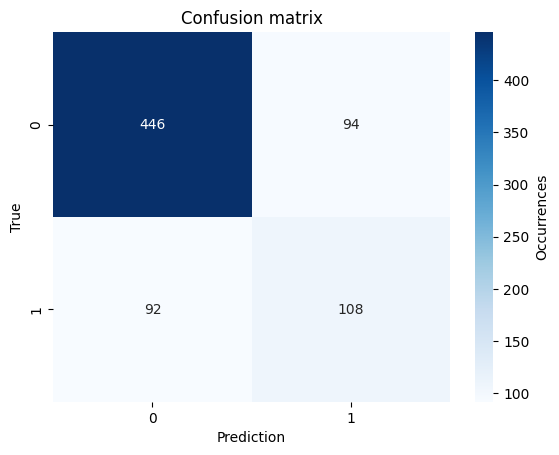

In [10]:
# visualize (final) confusion matrix on validation set
y_prob = model(X_val).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)
print('The accuracy is:', acc_val)
confusion_matrix(y_val, y_pred)

Precision: 0.7494
Recall:    0.7486
F1-score:  0.7490
Class 0 - Precision: 0.8290, Recall: 0.8259, F1-score: 0.8275
Class 1 - Precision: 0.5347, Recall: 0.5400, F1-score: 0.5373


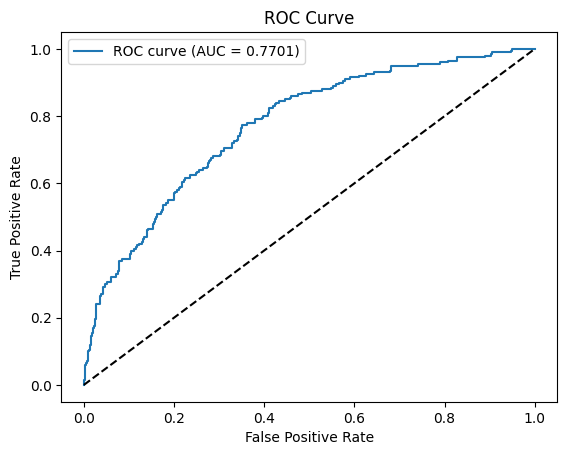

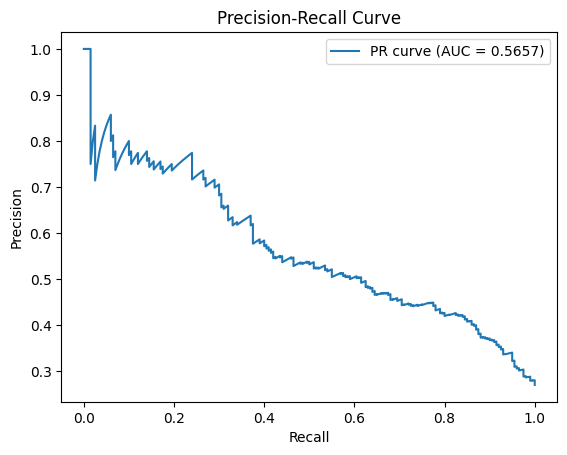

In [11]:
# Convert torch tensors to numpy arrays
y_val_np = y_val.numpy()
y_pred_np = y_pred.numpy()
y_prob_np = y_prob[:, 1].detach().numpy()  # Probability for class 1

# Precision, Recall, F1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_val_np, y_pred_np, average='weighted')
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
# Precision, Recall, F1-score for both classes
precision_all, recall_all, f1_all, _ = precision_recall_fscore_support(y_val_np, y_pred_np, average=None)
for i, (p, r, f) in enumerate(zip(precision_all, recall_all, f1_all)):
    print(f"Class {i} - Precision: {p:.4f}, Recall: {r:.4f}, F1-score: {f:.4f}")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_val_np, y_prob_np)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve & AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_val_np, y_prob_np)
pr_auc = average_precision_score(y_val_np, y_prob_np)
plt.figure()
plt.plot(recall_curve, precision_curve, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

The accuracy is: 0.766531713900135


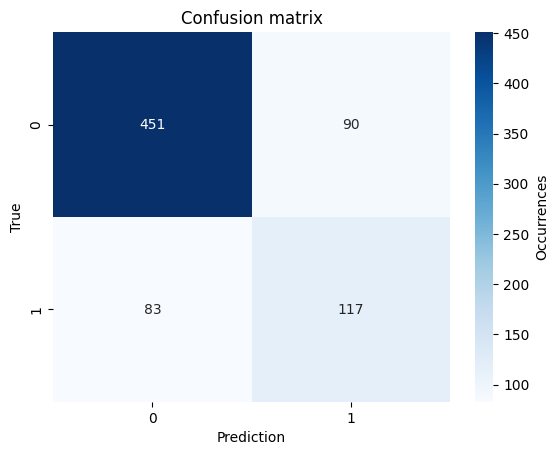

In [12]:
# visualize (final) confusion matrix on test set
y_prob = model(X_test).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_test = accuracy_fn(y_true=y_test, y_pred=y_pred)
print('The accuracy is:', acc_test)
confusion_matrix(y_test, y_pred)

Precision: 0.7692
Recall:    0.7665
F1-score:  0.7678
Class 0 - Precision: 0.8446, Recall: 0.8336, F1-score: 0.8391
Class 1 - Precision: 0.5652, Recall: 0.5850, F1-score: 0.5749


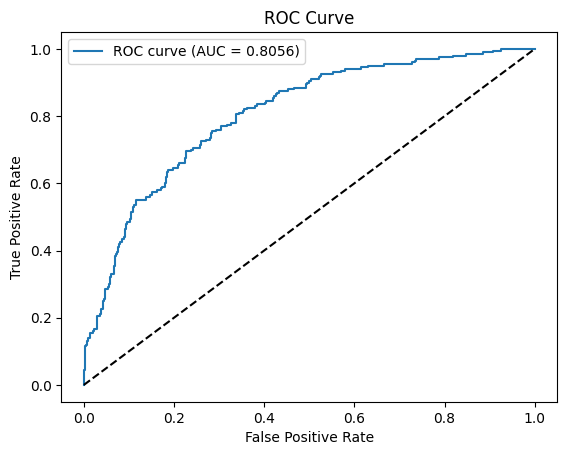

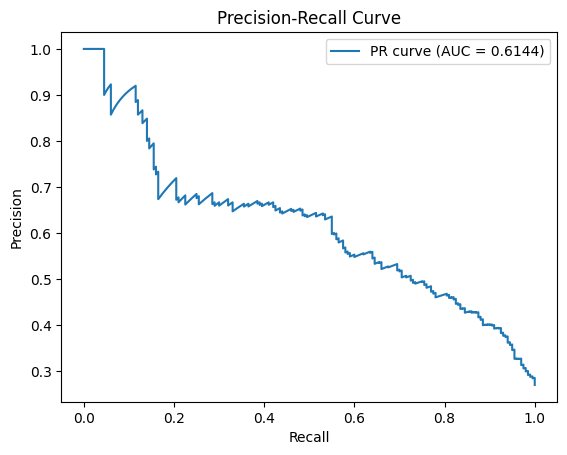

In [13]:
# Convert torch tensors to numpy arrays
y_test_np = y_test.numpy()
y_pred_np = y_pred.numpy()
y_prob_np = y_prob[:, 1].detach().numpy()  # Probability for class 1

# Precision, Recall, F1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average='weighted')
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
# Precision, Recall, F1-score for both classes
precision_all, recall_all, f1_all, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average=None)
for i, (p, r, f) in enumerate(zip(precision_all, recall_all, f1_all)):
    print(f"Class {i} - Precision: {p:.4f}, Recall: {r:.4f}, F1-score: {f:.4f}")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_test_np, y_prob_np)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve & AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test_np, y_prob_np)
pr_auc = average_precision_score(y_test_np, y_prob_np)
plt.figure()
plt.plot(recall_curve, precision_curve, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

<h3>Trying with a 2 layer model</h3>

In [14]:
# Define the neural network
class Model_classification(nn.Module): 
    def __init__(
        self, 
        in_features, # number of input features
        out_features, # number of output features
        hidden_1, # number of neurons in the 1st hidden layer
        hidden_2, # number of neurons in the 2nd hidden layer
    ):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=in_features, out_features=hidden_1) # 1st linear layer
        self.layer_2 = nn.Linear(in_features=hidden_1, out_features=hidden_2) # 2nd linear layer

        self.layer_output = nn.Linear(in_features=hidden_2, out_features=out_features) # output layer
        self.activation_1 = nn.Tanh() # activation function
        #self.activation_2 = nn.Softmax(dim=1) # activation function

    # define feedforward process
    def forward(self, x):
        #x = x.flatten(start_dim=1) #to go from 28x28 image tensor to 784 input tensor
        out = self.activation_1(self.layer_1(x)) #output of 1st hidden layer
        out = self.activation_1(self.layer_2(out)) #output of 2nd hidden layer
        #out = self.activation_1(self.layer_3(out))
        #out = self.activation_2(self.layer_output(out)) #output of the nn
        out = self.layer_output(out) 
        
        return out

In [24]:
# Define parameter grid
param_grid = {
    'learning_rate': [1e-5],
    'hidden_1': [7500, 5000, 2500],
    'hidden_2': [5000, 2500, 1250],
    'batch_size': [32, 64]
}

# Generate all combinations
keys, values = zip(*param_grid.items())
param_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

best_val_acc = 0
best_params = None

for params in param_combinations:
    # Create model with current parameters
    model = Model_classification(
        in_features=dim_features,
        out_features=2,
        hidden_1=params['hidden_1'],
        hidden_2=params['hidden_2'],
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=params['learning_rate'])
    batch_size = params['batch_size']
    batches = create_batches(X_train, y_train, batch_size)

    epoch = 0
    current_max_acc = 0
    stop = False
    max_cumulated_epochs = 5
    current_cumulated_epochs = 0
    
    while not stop:
        # model training phase
        model.train()
        for _, (data_batch, label_batch) in enumerate(batches):
            y_prob = model(data_batch).squeeze() # get the output probability of predictions
            loss_batch = loss_fn(y_prob, label_batch) # calculate the loss
            optimizer.zero_grad() # reset the gradients of model parameters
            loss_batch.backward() # backpropagate the prediction loss
            optimizer.step() # adjust the parameters by the gradients 

        # model evaluation phase
        model.eval()
        
        # training set
        y_prob = model(X_train).squeeze()
        y_pred = torch.argmax(y_prob, dim=-1) # get the label
        acc_train = accuracy_fn(y_true=y_train, y_pred=y_pred)

        # validation set
        y_prob = model(X_val).squeeze()
        y_pred = torch.argmax(y_prob, dim=-1) 
        acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)

        if current_max_acc -  acc_val < 0: 
            current_max_acc =  acc_val
        else:
            current_cumulated_epochs += 1
            if current_cumulated_epochs >= max_cumulated_epochs:
                stop = True

        if acc_train==1.0:
            stop=True
    print(f"Params: {params}, Val Acc: {acc_val:.4f}")
    if acc_val > best_val_acc:
        best_val_acc = acc_val
        best_params = params

print("Best parameters:", best_params)

Params: {'learning_rate': 1e-05, 'hidden_1': 7500, 'hidden_2': 5000, 'batch_size': 32}, Val Acc: 0.7054
Params: {'learning_rate': 1e-05, 'hidden_1': 7500, 'hidden_2': 5000, 'batch_size': 64}, Val Acc: 0.7095
Params: {'learning_rate': 1e-05, 'hidden_1': 7500, 'hidden_2': 2500, 'batch_size': 32}, Val Acc: 0.7135
Params: {'learning_rate': 1e-05, 'hidden_1': 7500, 'hidden_2': 2500, 'batch_size': 64}, Val Acc: 0.7054
Params: {'learning_rate': 1e-05, 'hidden_1': 7500, 'hidden_2': 1250, 'batch_size': 32}, Val Acc: 0.7068
Params: {'learning_rate': 1e-05, 'hidden_1': 7500, 'hidden_2': 1250, 'batch_size': 64}, Val Acc: 0.7027
Params: {'learning_rate': 1e-05, 'hidden_1': 5000, 'hidden_2': 5000, 'batch_size': 32}, Val Acc: 0.7081
Params: {'learning_rate': 1e-05, 'hidden_1': 5000, 'hidden_2': 5000, 'batch_size': 64}, Val Acc: 0.6946
Params: {'learning_rate': 1e-05, 'hidden_1': 5000, 'hidden_2': 2500, 'batch_size': 32}, Val Acc: 0.6959
Params: {'learning_rate': 1e-05, 'hidden_1': 5000, 'hidden_2': 2

In [15]:
#To analyze results without executing the whole grid search again
best_params = {'learning_rate': 1e-05, 'hidden_1': 2500, 'hidden_2': 2500, 'batch_size': 32}

In [16]:
# Train the model with the best parameters found in best_params
model = Model_classification(
    in_features=dim_features,
    out_features=2,
    hidden_1=best_params['hidden_1'],
    hidden_2=best_params['hidden_2'],
)
optimizer = torch.optim.Adam(model.parameters(), lr=best_params['learning_rate'])

batch_size = best_params['batch_size']
batches = create_batches(X_train, y_train, batch_size)

epoch=0
loss_train_all = []
loss_val_all = []
acc_train_all = []
acc_val_all = []
current_max_acc = 0
current_cumulated_epochs = 0
max_cumulated_epochs = 10
stop = False

while not stop:
    # Training phase
    model.train()
    loss_all = []
    for data_batch, label_batch in batches:
        y_prob = model(data_batch)
        loss = loss_fn(y_prob, label_batch)
        loss_all.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    # Evaluation phase
    model.eval()
    with torch.no_grad():
        # Training set
        y_prob_train = model(X_train)
        y_pred_train = torch.argmax(y_prob_train, dim=1)
        acc_train = accuracy_fn(y_train, y_pred_train)
        
        # Validation set
        y_prob_val = model(X_val)
        loss_val = loss_fn(y_prob_val, y_val)
        y_pred_val = torch.argmax(y_prob_val, dim=1)
        acc_val = accuracy_fn(y_val, y_pred_val)
    
    # Collect results
    loss_train_all.append(np.mean(loss_all))
    loss_val_all.append(loss_val.item())
    acc_train_all.append(acc_train)
    acc_val_all.append(acc_val)
    
    print(f'Epoch: {epoch+1} | Train Loss: {loss_train_all[-1]:.5f}, Val Loss: {loss_val_all[-1]:.5f}, Train Acc: {acc_train:.4f}, Val Acc: {acc_val:.4f}')
    epoch += 1

    # if the evaluated accuracy is not larger than the maximum accuracy recorded, we increase the cumulation of epochs of 1
    if current_max_acc -  acc_val < 0: 
        current_max_acc =  acc_val
        #save model state
        torch.save(model.state_dict(), 'best_model.pth')
    else:
        current_cumulated_epochs += 1
        if current_cumulated_epochs >= max_cumulated_epochs:
            stop = True

# Load the best model
model.load_state_dict(torch.load('best_model.pth'))

Epoch: 1 | Train Loss: 0.64002, Val Loss: 0.59445, Train Acc: 0.7602, Val Acc: 0.7054
Epoch: 2 | Train Loss: 0.53049, Val Loss: 0.56806, Train Acc: 0.8312, Val Acc: 0.7257
Epoch: 3 | Train Loss: 0.43968, Val Loss: 0.55045, Train Acc: 0.9059, Val Acc: 0.7311
Epoch: 4 | Train Loss: 0.33693, Val Loss: 0.54431, Train Acc: 0.9644, Val Acc: 0.7392
Epoch: 5 | Train Loss: 0.23758, Val Loss: 0.55883, Train Acc: 0.9864, Val Acc: 0.7365
Epoch: 6 | Train Loss: 0.16027, Val Loss: 0.59492, Train Acc: 0.9902, Val Acc: 0.7405
Epoch: 7 | Train Loss: 0.10855, Val Loss: 0.64480, Train Acc: 0.9913, Val Acc: 0.7311
Epoch: 8 | Train Loss: 0.07639, Val Loss: 0.69962, Train Acc: 0.9936, Val Acc: 0.7176
Epoch: 9 | Train Loss: 0.05648, Val Loss: 0.75464, Train Acc: 0.9948, Val Acc: 0.7108
Epoch: 10 | Train Loss: 0.04348, Val Loss: 0.80851, Train Acc: 0.9957, Val Acc: 0.7014
Epoch: 11 | Train Loss: 0.03444, Val Loss: 0.86091, Train Acc: 0.9968, Val Acc: 0.6959
Epoch: 12 | Train Loss: 0.02778, Val Loss: 0.91181, 

<All keys matched successfully>

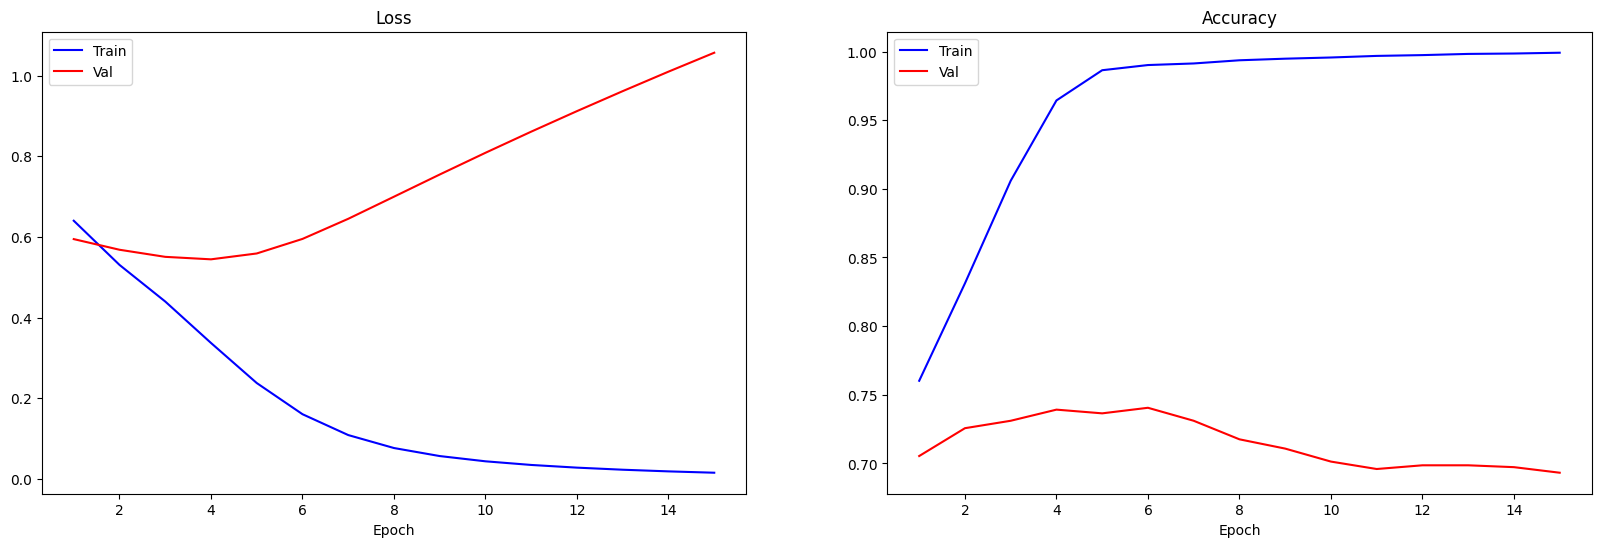

The accuracy is: 0.7405405405405405


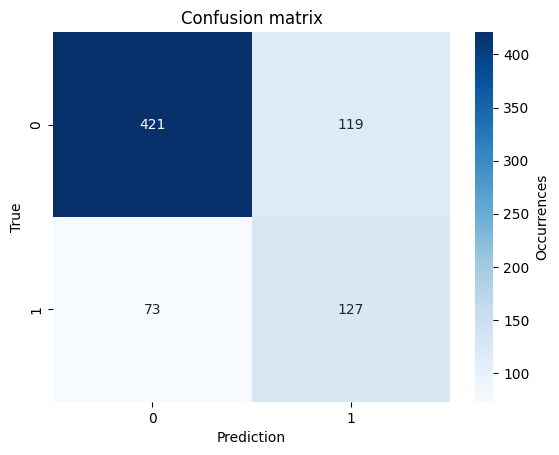

In [17]:
# visualize the evolution of losses and accuracies
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(20,6))

ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.plot(range(1, len(loss_train_all) + 1), loss_train_all, label='Train', color='blue')
ax1.plot(range(1, len(loss_val_all) + 1), loss_val_all, label='Val', color='red')
ax1.legend()

ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.plot(range(1, len(acc_train_all) + 1), acc_train_all, label='Train', color='blue')
ax2.plot(range(1, len(acc_val_all) + 1), acc_val_all, label='Val', color='red')
ax2.legend()

plt.show()

# visualize confusion matrix on validation set
y_prob = model(X_val).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)
print('The accuracy is:', acc_val)
confusion_matrix(y_val, y_pred)

Compute precision, recall F1 score for the validation set. And plot ROC & AUC

Precision: 0.7614
Recall:    0.7405
F1-score:  0.7481
Class 0 - Precision: 0.8522, Recall: 0.7796, F1-score: 0.8143
Class 1 - Precision: 0.5163, Recall: 0.6350, F1-score: 0.5695


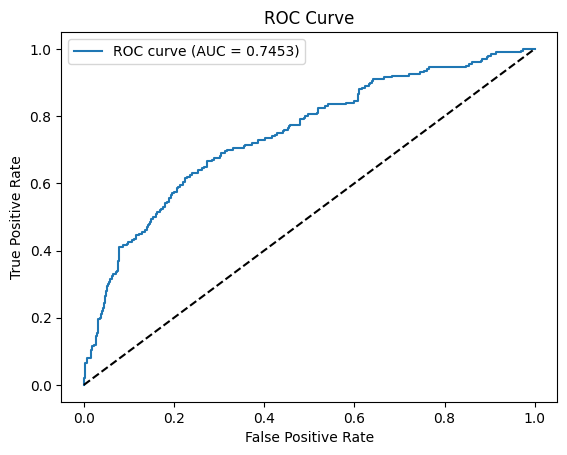

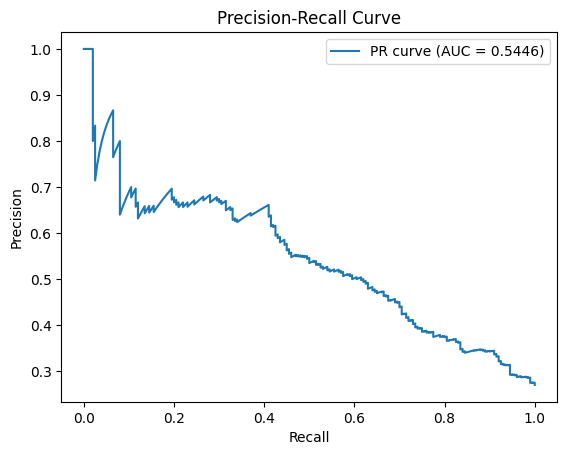

In [18]:
# Convert torch tensors to numpy arrays
y_val_np = y_val.numpy()
y_pred_np = y_pred.numpy()
y_prob_np = y_prob[:, 1].detach().numpy()  # Probability for class 1

# Precision, Recall, F1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_val_np, y_pred_np, average='weighted')
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
# Precision, Recall, F1-score for both classes
precision_all, recall_all, f1_all, _ = precision_recall_fscore_support(y_val_np, y_pred_np, average=None)
for i, (p, r, f) in enumerate(zip(precision_all, recall_all, f1_all)):
    print(f"Class {i} - Precision: {p:.4f}, Recall: {r:.4f}, F1-score: {f:.4f}")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_val_np, y_prob_np)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve & AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_val_np, y_prob_np)
pr_auc = average_precision_score(y_val_np, y_prob_np)
plt.figure()
plt.plot(recall_curve, precision_curve, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

The accuracy is: 0.7462887989203779


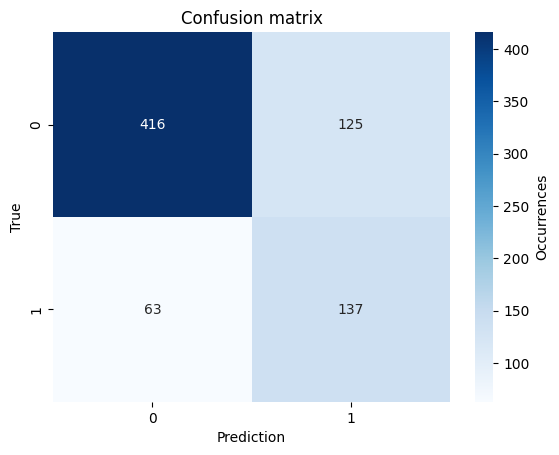

In [19]:
# visualize (final) confusion matrix on test set
y_prob = model(X_test).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_test = accuracy_fn(y_true=y_test, y_pred=y_pred)
print('The accuracy is:', acc_test)
confusion_matrix(y_test, y_pred)

Compute precision, recall F1 score for the validation set. And plot ROC & AUC

Precision: 0.7752
Recall:    0.7463
F1-score:  0.7556
Class 0 - Precision: 0.8685, Recall: 0.7689, F1-score: 0.8157
Class 1 - Precision: 0.5229, Recall: 0.6850, F1-score: 0.5931


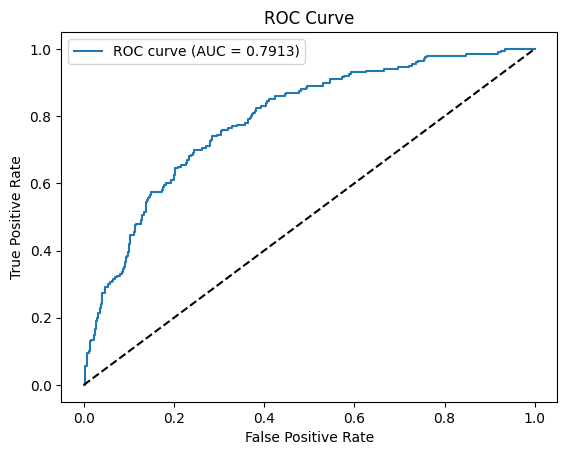

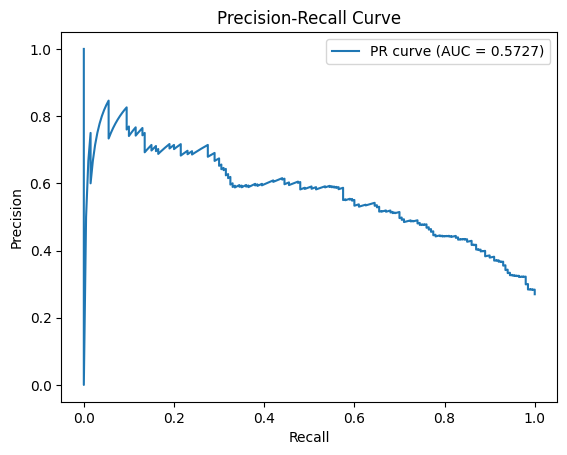

In [20]:
# Convert torch tensors to numpy arrays
y_test_np = y_test.numpy()
y_pred_np = y_pred.numpy()
y_prob_np = y_prob[:, 1].detach().numpy()  # Probability for class 1

# Precision, Recall, F1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average='weighted')
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
# Precision, Recall, F1-score for both classes
precision_all, recall_all, f1_all, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average=None)
for i, (p, r, f) in enumerate(zip(precision_all, recall_all, f1_all)):
    print(f"Class {i} - Precision: {p:.4f}, Recall: {r:.4f}, F1-score: {f:.4f}")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_test_np, y_prob_np)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve & AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test_np, y_prob_np)
pr_auc = average_precision_score(y_test_np, y_prob_np)
plt.figure()
plt.plot(recall_curve, precision_curve, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

<h3>Trying a 3 layer with leaky-ReLu</h3>

In [30]:
# Define the neural network
class Model_classification(nn.Module): 
    def __init__(
        self, 
        in_features, # number of input features
        out_features, # number of output features
        hidden_1, # number of neurons in the 1st hidden layer
        hidden_2, # number of neurons in the 2nd hidden layer
        hidden_3 # number of neurons in the 3rd hidden layer
    ):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=in_features, out_features=hidden_1) # 1st linear layer
        self.layer_2 = nn.Linear(in_features=hidden_1, out_features=hidden_2) # 2nd linear layer
        self.layer_3 = nn.Linear(in_features=hidden_2, out_features=hidden_3) # 3rd linear layer
        self.layer_output = nn.Linear(in_features=hidden_3, out_features=out_features) # output layer
        
        #self.activation_1 = nn.Tanh() # activation function
        #self.activation_2 = nn.Softmax(dim=1) # activation function
        self.activation_3 = nn.LeakyReLU() # activation function

    # define feedforward process
    def forward(self, x):
        #x = x.flatten(start_dim=1) #to go from 28x28 image tensor to 784 input tensor
        out = self.activation_3(self.layer_1(x)) #output of 1st hidden layer
        out = self.activation_3(self.layer_2(out)) #output of 2nd hidden layer
        out = self.activation_3(self.layer_3(out))
        #out = self.activation_2(self.layer_output(out)) #output of the nn
        out = self.layer_output(out) 
        
        return out

In [31]:
# Define parameter grid
param_grid = {
    'learning_rate': [1e-5],
    'hidden_1': [1000,  2000, 4000],
    'hidden_2': [1500, 750, 2500],
    'hidden_3': [250, 500, 1000],
    'batch_size': [32, 64]
}

# Generate all combinations
keys, values = zip(*param_grid.items())
param_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

best_val_acc = 0
best_params = None

for params in param_combinations:
    # Create model with current parameters
    model = Model_classification(
        in_features=dim_features,
        out_features=2,
        hidden_1=params['hidden_1'],
        hidden_2=params['hidden_2'],
        hidden_3=params['hidden_3']
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=params['learning_rate'])
    batch_size = params['batch_size']
    batches = create_batches(X_train, y_train, batch_size)

    epoch = 0
    current_max_acc = 0
    stop = False
    max_cumulated_epochs = 5
    current_cumulated_epochs = 0
    
    while not stop:
        # model training phase
        model.train()
        for _, (data_batch, label_batch) in enumerate(batches):
            y_prob = model(data_batch).squeeze() # get the output probability of predictions
            loss_batch = loss_fn(y_prob, label_batch) # calculate the loss
            optimizer.zero_grad() # reset the gradients of model parameters
            loss_batch.backward() # backpropagate the prediction loss
            optimizer.step() # adjust the parameters by the gradients 

        # model evaluation phase
        model.eval()
        
        # training set
        y_prob = model(X_train).squeeze()
        y_pred = torch.argmax(y_prob, dim=-1) # get the label
        acc_train = accuracy_fn(y_true=y_train, y_pred=y_pred)

        # validation set
        y_prob = model(X_val).squeeze()
        y_pred = torch.argmax(y_prob, dim=-1) 
        acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)

        if current_max_acc -  acc_val < 0: 
            current_max_acc =  acc_val
        else:
            current_cumulated_epochs += 1
            if current_cumulated_epochs >= max_cumulated_epochs:
                stop = True

        if acc_train==1.0:
            stop=True
    print(f"Params: {params}, Val Acc: {acc_val:.4f}")
    if acc_val > best_val_acc:
        best_val_acc = acc_val
        best_params = params

print("Best parameters:", best_params)

Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 250, 'batch_size': 32}, Val Acc: 0.7676
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 250, 'batch_size': 64}, Val Acc: 0.7649
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 500, 'batch_size': 32}, Val Acc: 0.7676
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 500, 'batch_size': 64}, Val Acc: 0.7635
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 1000, 'batch_size': 32}, Val Acc: 0.7595
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 1000, 'batch_size': 64}, Val Acc: 0.7595
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 250, 'batch_size': 32}, Val Acc: 0.7730
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 250, 'batch_size': 64}, Val Acc: 0.7838
Params: {'learning_rate': 1e-05,

In [ ]:
# To analyze results without executing the whole grid search again
# best_params = {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 250, 'batch_size': 64}

In [32]:
# Train the model with the best parameters found in best_params
model = Model_classification(
    in_features=dim_features,
    out_features=2,
    hidden_1=best_params['hidden_1'],
    hidden_2=best_params['hidden_2'],
    hidden_3=best_params['hidden_3']
)
optimizer = torch.optim.Adam(model.parameters(), lr=best_params['learning_rate'])

batch_size = best_params['batch_size']
batches = create_batches(X_train, y_train, batch_size)

epoch=0
loss_train_all = []
loss_val_all = []
acc_train_all = []
acc_val_all = []
current_max_acc = 0
current_cumulated_epochs = 0
max_cumulated_epochs = 10
stop = False

while not stop:
    # Training phase
    model.train()
    loss_all = []
    for data_batch, label_batch in batches:
        y_prob = model(data_batch)
        loss = loss_fn(y_prob, label_batch)
        loss_all.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    # Evaluation phase
    model.eval()
    with torch.no_grad():
        # Training set
        y_prob_train = model(X_train)
        y_pred_train = torch.argmax(y_prob_train, dim=1)
        acc_train = accuracy_fn(y_train, y_pred_train)
        
        # Validation set
        y_prob_val = model(X_val)
        loss_val = loss_fn(y_prob_val, y_val)
        y_pred_val = torch.argmax(y_prob_val, dim=1)
        acc_val = accuracy_fn(y_val, y_pred_val)
    
    # Collect results
    loss_train_all.append(np.mean(loss_all))
    loss_val_all.append(loss_val.item())
    acc_train_all.append(acc_train)
    acc_val_all.append(acc_val)
    
    print(f'Epoch: {epoch+1} | Train Loss: {loss_train_all[-1]:.5f}, Val Loss: {loss_val_all[-1]:.5f}, Train Acc: {acc_train:.4f}, Val Acc: {acc_val:.4f}')
    epoch += 1

    # if the evaluated accuracy is not larger than the maximum accuracy recorded, we increase the cumulation of epochs of 1
    if current_max_acc -  acc_val < 0: 
        current_max_acc =  acc_val
        #save model state
        torch.save(model.state_dict(), 'best_model.pth')
    else:
        current_cumulated_epochs += 1
        if current_cumulated_epochs >= max_cumulated_epochs:
            stop = True

# Load the best model
model.load_state_dict(torch.load('best_model.pth'))

Epoch: 1 | Train Loss: 0.65563, Val Loss: 0.61406, Train Acc: 0.7301, Val Acc: 0.7297
Epoch: 2 | Train Loss: 0.57532, Val Loss: 0.55962, Train Acc: 0.7301, Val Acc: 0.7297
Epoch: 3 | Train Loss: 0.52773, Val Loss: 0.53632, Train Acc: 0.7301, Val Acc: 0.7297
Epoch: 4 | Train Loss: 0.49124, Val Loss: 0.51802, Train Acc: 0.7353, Val Acc: 0.7297
Epoch: 5 | Train Loss: 0.45157, Val Loss: 0.50030, Train Acc: 0.7787, Val Acc: 0.7473
Epoch: 6 | Train Loss: 0.40608, Val Loss: 0.48617, Train Acc: 0.8407, Val Acc: 0.7541
Epoch: 7 | Train Loss: 0.35423, Val Loss: 0.47883, Train Acc: 0.8807, Val Acc: 0.7595
Epoch: 8 | Train Loss: 0.29582, Val Loss: 0.47946, Train Acc: 0.9233, Val Acc: 0.7568
Epoch: 9 | Train Loss: 0.23243, Val Loss: 0.48739, Train Acc: 0.9566, Val Acc: 0.7608
Epoch: 10 | Train Loss: 0.16816, Val Loss: 0.50208, Train Acc: 0.9820, Val Acc: 0.7635
Epoch: 11 | Train Loss: 0.11236, Val Loss: 0.52365, Train Acc: 0.9913, Val Acc: 0.7595
Epoch: 12 | Train Loss: 0.07352, Val Loss: 0.55017, 

<All keys matched successfully>

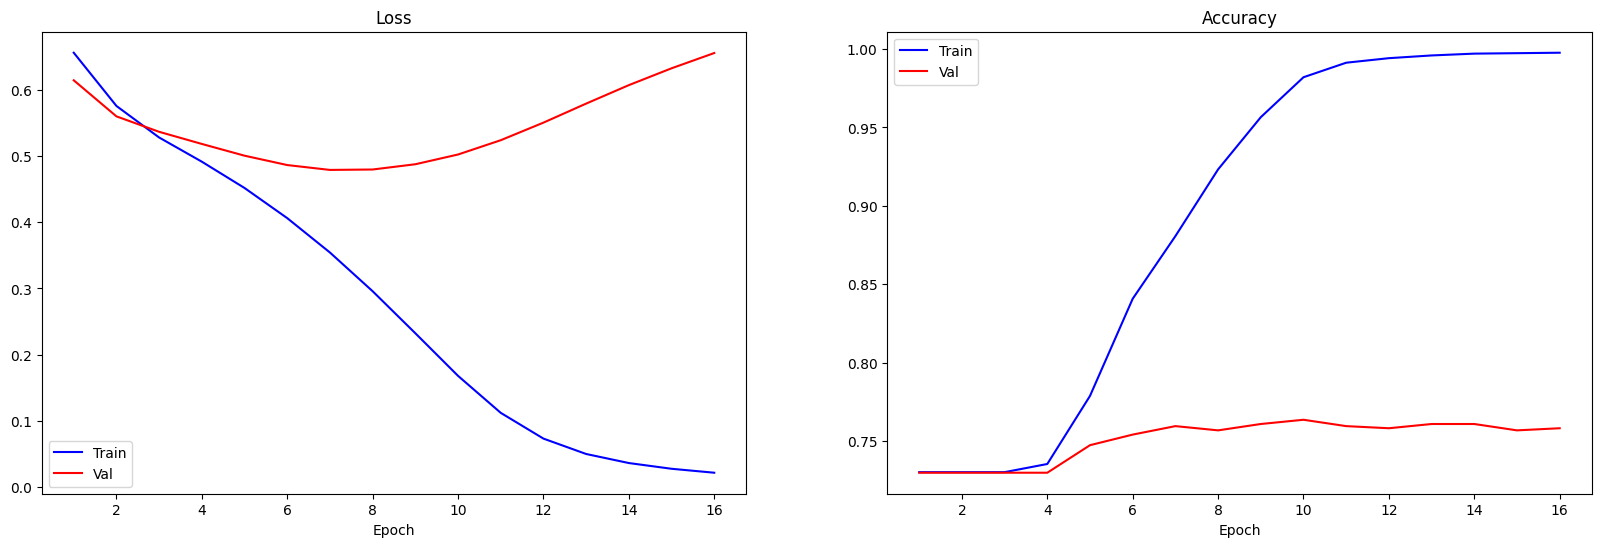

The accuracy is: 0.7635135135135135


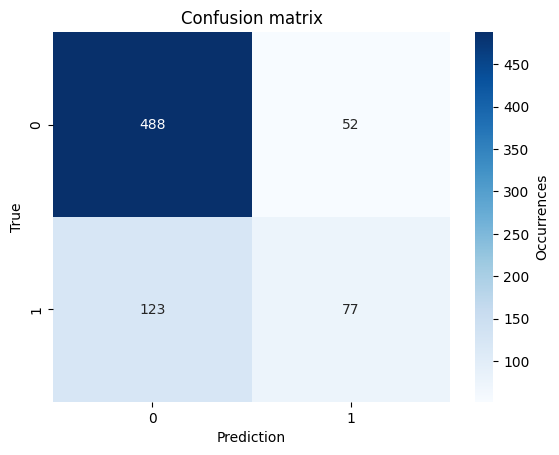

In [37]:
# visualize the evolution of losses and accuracies
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(20,6))

ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.plot(range(1, len(loss_train_all) + 1), loss_train_all, label='Train', color='blue')
ax1.plot(range(1, len(loss_val_all) + 1), loss_val_all, label='Val', color='red')
ax1.legend()

ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.plot(range(1, len(acc_train_all) + 1),acc_train_all, label='Train', color='blue')
ax2.plot(range(1, len(acc_val_all) + 1), acc_val_all, label='Val', color='red')
ax2.legend()

plt.show()

# visualize confusion matrix on validation set
y_prob = model(X_val).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)
print('The accuracy is:', acc_val)
confusion_matrix(y_val, y_pred)

Compute precision, recall F1 score for the validation set. And plot ROC & AUC

Precision: 0.7442
Recall:    0.7635
F1-score:  0.7453
Class 0 - Precision: 0.7987, Recall: 0.9037, F1-score: 0.8480
Class 1 - Precision: 0.5969, Recall: 0.3850, F1-score: 0.4681


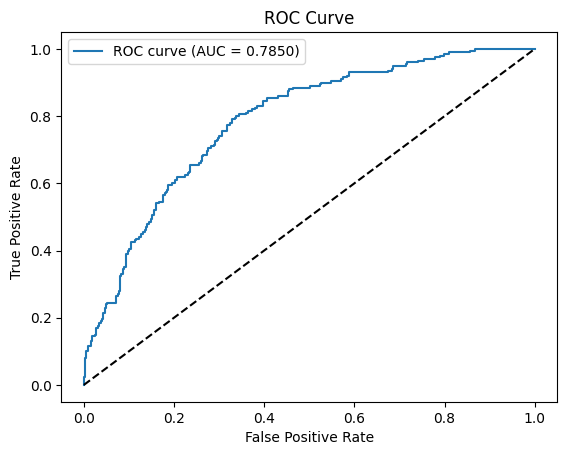

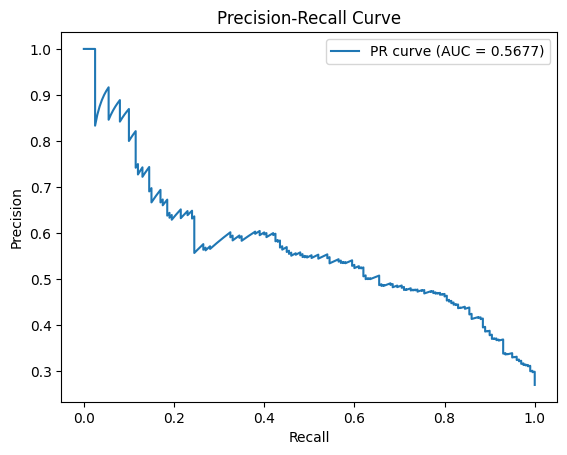

In [38]:
# Convert torch tensors to numpy arrays
y_val_np = y_val.numpy()
y_pred_np = y_pred.numpy()
y_prob_np = y_prob[:, 1].detach().numpy()  # Probability for class 1

# Precision, Recall, F1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_val_np, y_pred_np, average='weighted')
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
# Precision, Recall, F1-score for both classes
precision_all, recall_all, f1_all, _ = precision_recall_fscore_support(y_val_np, y_pred_np, average=None)
for i, (p, r, f) in enumerate(zip(precision_all, recall_all, f1_all)):
    print(f"Class {i} - Precision: {p:.4f}, Recall: {r:.4f}, F1-score: {f:.4f}")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_val_np, y_prob_np)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve & AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_val_np, y_prob_np)
pr_auc = average_precision_score(y_val_np, y_prob_np)
plt.figure()
plt.plot(recall_curve, precision_curve, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

The accuracy is: 0.7732793522267206


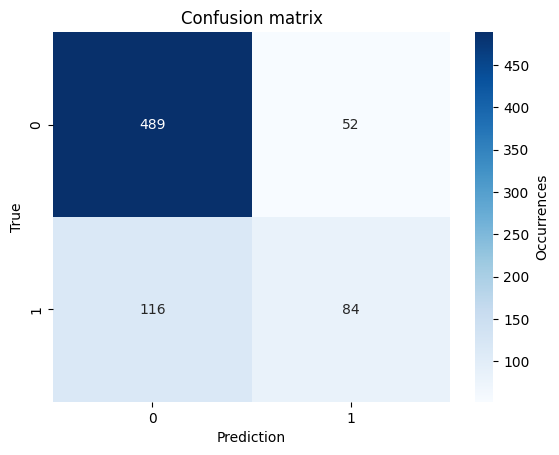

In [39]:
# visualize (final) confusion matrix on test set
y_prob = model(X_test).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_test = accuracy_fn(y_true=y_test, y_pred=y_pred)
print('The accuracy is:', acc_test)
confusion_matrix(y_test, y_pred)

Compute precision, recall F1 score for the validation set. And plot ROC & AUC

Precision: 0.7568
Recall:    0.7733
F1-score:  0.7580
Class 0 - Precision: 0.8083, Recall: 0.9039, F1-score: 0.8534
Class 1 - Precision: 0.6176, Recall: 0.4200, F1-score: 0.5000


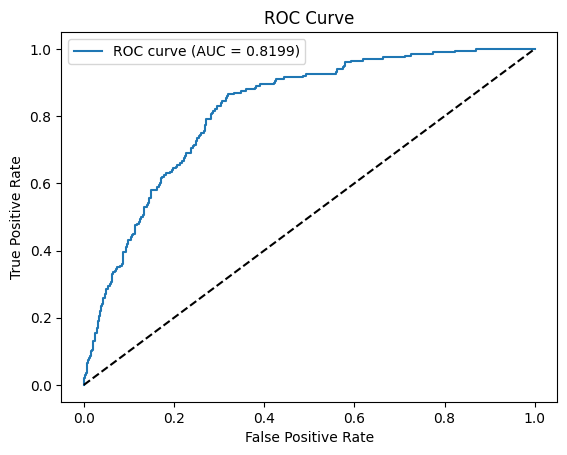

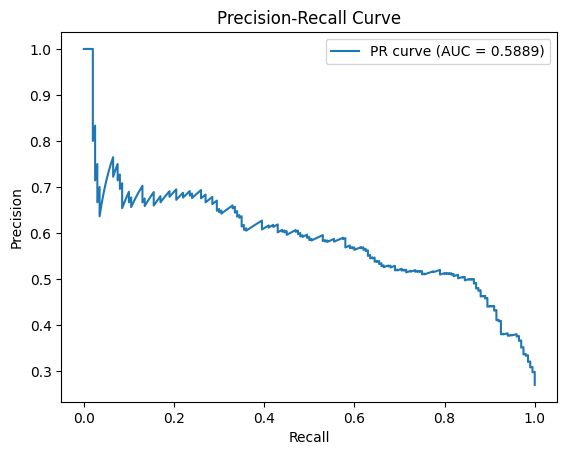

In [40]:
# Convert torch tensors to numpy arrays
y_test_np = y_test.numpy()
y_pred_np = y_pred.numpy()
y_prob_np = y_prob[:, 1].detach().numpy()  # Probability for class 1

# Precision, Recall, F1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average='weighted')
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
# Precision, Recall, F1-score for both classes
precision_all, recall_all, f1_all, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average=None)
for i, (p, r, f) in enumerate(zip(precision_all, recall_all, f1_all)):
    print(f"Class {i} - Precision: {p:.4f}, Recall: {r:.4f}, F1-score: {f:.4f}")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_test_np, y_prob_np)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve & AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test_np, y_prob_np)
pr_auc = average_precision_score(y_test_np, y_prob_np)
plt.figure()
plt.plot(recall_curve, precision_curve, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()